In [52]:
#import libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


In [53]:
#intialize data set
#generating random data points that can be visvually clustred into two groups

df = pd.read_csv("Mall_Customers.csv")
points1 = df[['Annual Income (k$)','Spending Score (1-100)']]

#scalar
scalar = StandardScaler()
X_scaled = scalar.fit_transform(points1)


<function matplotlib.pyplot.show(close=None, block=None)>

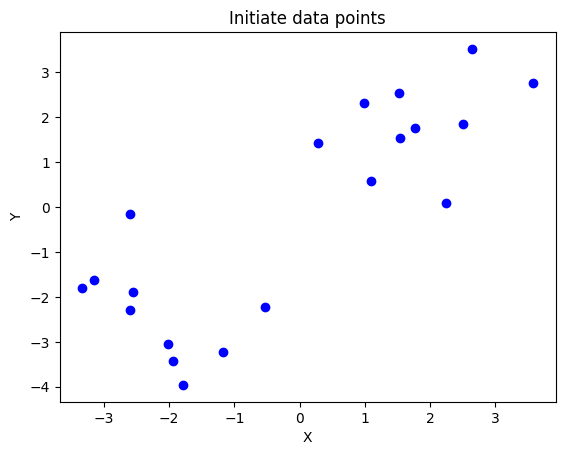

In [55]:
#intiate plotting

plt.scatter(points[:,0],points[:,1],c='blue',marker='o')
plt.title('Initiate data points')
plt.xlabel('X')
plt.ylabel('Y')
plt.show

In [58]:
#intialize random centroids

centroids = points[np.random.choice(points.shape[0],2,replace=False)]

In [59]:
def plot_clusters(points, centroids,labels,title):
    plt.scatter(points[:,0],points1[:,1],c=labels,cmap='coolwarm',s=100)
    plt.title('Initiate data points')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.show

def compute_wcss(points,centroids,labels):
    wcss = 0
    for i in range(centroids.shape[0]):
        wcss += np.sum((points[labels == i]-centroids[i])**2)
    return wcss


In [60]:
# plot the cluster using the helper functions

def kmeans_with_wcss(points,centroids,max_iters=10):
    wcss_values = []

    for i in range(max_iters):

        distance = np.linalg.norm(points1[:,np.newaxis]-centroids,axis=2)
        labels = np.argmin(distance,axis=1)

        plot_clusters(points,centroids,labels,f'Iterations{i +1}: Expectetation Step')

        new_centroids = np.array([points[labels == j].mean(axis=0) for j in range(centroids.shape[0])])

        wcss = compute_wcss(points,new_centroids,labels)
        wcss_values.append(wcss)

       # Plot clusters after maximization step
        plot_clusters(points, new_centroids, labels, f'Iteration {i + 1}: Maximization Step - WCSS: {wcss:.2f}')

        # Check for convergence
        if np.all(centroids == new_centroids):
            print(f"Converged after {i + 1} iterations.")
            break

        centroids = new_centroids

    # Plot the WCSS values over iterations
    plt.plot(range(1, len(wcss_values) + 1), wcss_values, marker='o')
    plt.title('WCSS over Iterations')
    plt.xlabel('Iteration')
    plt.ylabel('WCSS')
    plt.show()

In [63]:
# Run K-Means algorithm with WCSS tracking
centroids = points1[np.random.choice(points1.shape[0], 2, replace=False)]
kmeans_with_wcss(points1, centroids)

KeyError: "None of [Index([57, 96], dtype='int32')] are in the [columns]"